In [1]:

import os
import zipfile

ZIP_PATH = "/content/dataset_split.zip"
EXTRACT_PATH = "/content/bread_data"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extracted successfully!")
print(os.listdir(EXTRACT_PATH))


Dataset extracted successfully!
['dataset_split']


In [2]:

from pathlib import Path

root = Path("/content/bread_data")

# ZIP mein dataset_split folder ho sakta hai,
# ya train/val/test directly ho sakte hain.
if (root / "dataset_split").exists():
    root = root / "dataset_split"

print("Dataset location:", root)

for split in ["train", "val", "test"]:
    for label in ["fresh", "spoiled"]:
        folder = root / split / label
        count = len([
            p for p in folder.iterdir()
            if p.is_file()
        ]) if folder.exists() else 0

        print(f"{split}/{label}: {count}")



Dataset location: /content/bread_data/dataset_split
train/fresh: 261
train/spoiled: 68
val/fresh: 56
val/spoiled: 14
test/fresh: 57
test/spoiled: 16


In [3]:

import tensorflow as tf
import numpy as np

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    root / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["fresh", "spoiled"],
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    root / "val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["fresh", "spoiled"],
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    root / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["fresh", "spoiled"],
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Classes: 0 = Fresh, 1 = Spoiled")


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Found 329 files belonging to 2 classes.
Found 70 files belonging to 2 classes.
Found 73 files belonging to 2 classes.
Classes: 0 = Fresh, 1 = Spoiled


In [4]:

from tensorflow.keras import layers, models

augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
], name="augmentation")

scratch_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    augmentation,
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

scratch_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

scratch_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 249,153 (973.25 KB)

 Trainable params: 249,153 (973.25 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

fresh_count = len(list((root / "train" / "fresh").glob("*")))
spoiled_count = len(list((root / "train" / "spoiled").glob("*")))

total = fresh_count + spoiled_count

class_weights = {
    0: total / (2 * fresh_count),
    1: total / (2 * spoiled_count)
}

print("Class weights:", class_weights)

scratch_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "/content/best_scratch_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

scratch_history = scratch_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weights,
    callbacks=scratch_callbacks
)


Class weights: {0: 0.6302681992337165, 1: 2.4191176470588234}
Epoch 1/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 102ms/step - accuracy: 0.7112 - loss: 0.7028 - val_accuracy: 0.8000 - val_loss: 0.6599
Epoch 2/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step - accuracy: 0.7264 - loss: 0.6878 - val_accuracy: 0.8000 - val_loss: 0.6683
Epoch 3/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - accuracy: 0.6018 - loss: 0.6909 - val_accuracy: 0.6143 - val_loss: 0.6820
Epoch 4/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - accuracy: 0.7386 - loss: 0.6741 - val_accuracy: 0.7571 - val_loss: 0.6027
Epoch 5/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 111ms/step - accuracy: 0.4286 - loss: 0.6954 - val_accuracy: 0.2000 - val_loss: 0.6974
Epoch 6/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step - accuracy: 0.6626 - loss: 0.6948 - val_accuracy: 0.7429 - val_loss: 0.6811
Epoch 7/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - accuracy: 0.5410 - loss: 0.6942 - val_accuracy: 0.5571 - val_loss: 0.6936
Epoch 8/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms

In [6]:
# Step 8: Evaluate CNN From Scratch

train_loss, train_acc = scratch_model.evaluate(train_ds, verbose=0)
val_loss, val_acc = scratch_model.evaluate(val_ds, verbose=0)
test_loss, test_acc = scratch_model.evaluate(test_ds, verbose=0)

print(f"Training Accuracy:   {train_acc * 100:.2f}%")
print(f"Validation Accuracy: {val_acc * 100:.2f}%")
print(f"Testing Accuracy:    {test_acc * 100:.2f}%")

Training Accuracy:   78.12%
Validation Accuracy: 75.71%
Testing Accuracy:    76.71%


In [7]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = []
y_pred = []

for images, labels in test_ds:
    probabilities = scratch_model.predict(images, verbose=0).ravel()

    y_true.extend(labels.numpy().astype(int).ravel())
    y_pred.extend((probabilities >= 0.5).astype(int))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Fresh", "Spoiled"],
    digits=3,
    zero_division=0
))

Confusion Matrix:
[[55  2]
 [15  1]]

Classification Report:
              precision    recall  f1-score   support

       Fresh      0.786     0.965     0.866        57
     Spoiled      0.333     0.062     0.105        16

    accuracy                          0.767        73
   macro avg      0.560     0.514     0.486        73
weighted avg      0.687     0.767     0.699        73



In [9]:

import tensorflow as tf

# Fresh = 0, Spoiled = 1
fresh_ds = train_ds.unbatch().filter(
    lambda image, label: tf.equal(
        tf.squeeze(tf.cast(label, tf.int32)), 0
    )
)

spoiled_ds = train_ds.unbatch().filter(
    lambda image, label: tf.equal(
        tf.squeeze(tf.cast(label, tf.int32)), 1
    )
)

# Balanced sampling: 50% Fresh, 50% Spoiled
balanced_train_ds = tf.data.Dataset.sample_from_datasets(
    [
        fresh_ds.repeat(),
        spoiled_ds.repeat()
    ],
    weights=[0.5, 0.5],
    seed=42
)

steps_per_epoch = max(
    1,
    (fresh_count + spoiled_count) // BATCH_SIZE
)

balanced_train_ds = (
    balanced_train_ds
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Balanced training dataset ready!")
print("Steps per epoch:", steps_per_epoch)


Balanced training dataset ready!
Steps per epoch: 20


In [10]:

from tensorflow.keras import layers, models

augmentation_v2 = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1)
])

scratch_v2 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    augmentation_v2,
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

scratch_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.Precision(name="precision")
    ]
)

scratch_v2.summary()



Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [11]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

callbacks_v2 = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "/content/best_scratch_v2.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_v2 = scratch_v2.fit(
    balanced_train_ds,
    steps_per_epoch=steps_per_epoch,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_v2
)


Epoch 1/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 282ms/step - accuracy: 0.7625 - loss: 0.5080 - precision: 0.7391 - recall: 0.8293 - val_accuracy: 0.2286 - val_loss: 0.7049 - val_precision: 0.2059 - val_recall: 1.0000
Epoch 2/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 278ms/step - accuracy: 0.8125 - loss: 0.4490 - precision: 0.8462 - recall: 0.7857 - val_accuracy: 0.2000 - val_loss: 0.7312 - val_precision: 0.2000 - val_recall: 1.0000
Epoch 3/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 220ms/step - accuracy: 0.7531 - loss: 0.4699 - precision: 0.7414 - recall: 0.7914 - val_accuracy: 0.2000 - val_loss: 0.7628 - val_precision: 0.2000 - val_recall: 1.0000
Epoch 4/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 231ms/step - accuracy: 0.8625 - loss: 0.3522 - precision: 0.8116 - recall: 0.8615 - val_accuracy: 0.2000 - val_loss: 0.7937 - val_precision: 0.2000 - val_recall: 1.0000
Epoch 5/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 242ms/step - accuracy: 0.8156 - loss: 0.4212 - precision: 0.8741 - recall: 0.7375 - val_accuracy: 0.2000 - val_loss: 0

In [12]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

loss, accuracy, recall, precision = scratch_v2.evaluate(
    test_ds, verbose=0
)

y_true = []
y_pred = []

for images, labels in test_ds:
    probabilities = scratch_v2.predict(
        images, verbose=0
    ).ravel()

    y_true.extend(labels.numpy().astype(int).ravel())
    y_pred.extend((probabilities >= 0.5).astype(int))

print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Spoiled Recall: {recall * 100:.2f}%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Fresh", "Spoiled"],
    digits=3,
    zero_division=0
))


Test Accuracy: 24.66%
Spoiled Recall: 100.00%

Confusion Matrix:
[[ 2 55]
 [ 0 16]]

Classification Report:
              precision    recall  f1-score   support

       Fresh      1.000     0.035     0.068        57
     Spoiled      0.225     1.000     0.368        16

    accuracy                          0.247        73
   macro avg      0.613     0.518     0.218        73
weighted avg      0.830     0.247     0.134        73



In [13]:

import numpy as np

all_probs = []
all_labels = []

for images, labels in test_ds:
    probs = scratch_v2.predict(images, verbose=0).ravel()

    all_probs.extend(probs)
    all_labels.extend(labels.numpy().ravel())

all_probs = np.array(all_probs)
all_labels = np.array(all_labels).astype(int)

print("Fresh images ki average Spoiled probability:")
print(round(all_probs[all_labels == 0].mean(), 4))

print("\nSpoiled images ki average Spoiled probability:")
print(round(all_probs[all_labels == 1].mean(), 4))

print("\nMinimum prediction probability:")
print(round(all_probs.min(), 4))

print("\nMaximum prediction probability:")
print(round(all_probs.max(), 4))

print("\nPehli 15 prediction probabilities:")
print(np.round(all_probs[:15], 3))


Fresh images ki average Spoiled probability:
0.5107

Spoiled images ki average Spoiled probability:
0.5139

Minimum prediction probability:
0.4965

Maximum prediction probability:
0.5256

Pehli 15 prediction probabilities:
[0.506 0.515 0.515 0.522 0.51  0.509 0.503 0.5   0.525 0.517 0.507 0.524
 0.512 0.505 0.504]


In [14]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# Pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Pehle pretrained layers freeze rakhenge
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# Training ke waqt augmentation
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.05)(x)
x = layers.RandomZoom(0.1)(x)

# MobileNetV2 ke liye correct preprocessing
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

# Fresh = 0, Spoiled = 1
outputs = layers.Dense(1, activation="sigmoid")(x)

mobilenet_model = Model(inputs, outputs)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

mobilenet_model.summary()

print("MobileNetV2 ready!")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_2 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

MobileNetV2 ready!


In [15]:

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

mobilenet_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.000001
    ),
    ModelCheckpoint(
        "/content/best_mobilenetv2.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weights,
    callbacks=mobilenet_callbacks
)


Epoch 1/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 11s 208ms/step - accuracy: 0.5684 - loss: 0.7589 - precision: 0.2431 - recall: 0.5147 - val_accuracy: 0.4714 - val_loss: 0.7782 - val_precision: 0.2326 - val_recall: 0.7143 - learning_rate: 3.0000e-04
Epoch 2/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - accuracy: 0.6018 - loss: 0.6560 - precision: 0.2766 - recall: 0.5735 - val_accuracy: 0.6429 - val_loss: 0.6564 - val_precision: 0.3429 - val_recall: 0.8571 - learning_rate: 3.0000e-04
Epoch 3/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 124ms/step - accuracy: 0.6930 - loss: 0.5370 - precision: 0.3778 - recall: 0.7500 - val_accuracy: 0.7857 - val_loss: 0.5446 - val_precision: 0.4800 - val_recall: 0.8571 - learning_rate: 3.0000e-04
Epoch 4/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 125ms/step - accuracy: 0.8085 - loss: 0.4295 - precision: 0.5221 - recall: 0.8676 - val_accuracy: 0.8000 - val_loss: 0.5035 - val_precision: 0.5000 - val_recall: 0.8571 - learning_rate: 3.0000e-04
Epoch 5/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 126ms/

In [16]:

import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Accuracy check
train_results = mobilenet_model.evaluate(train_ds, verbose=0)
val_results = mobilenet_model.evaluate(val_ds, verbose=0)
test_results = mobilenet_model.evaluate(test_ds, verbose=0)

print("=== MobileNetV2 Accuracy ===")
print(f"Training Accuracy: {train_results[1]*100:.2f}%")
print(f"Validation Accuracy: {val_results[1]*100:.2f}%")
print(f"Testing Accuracy: {test_results[1]*100:.2f}%")

# Test images par predictions
y_true = []
y_pred = []

for images, labels in test_ds:
    probabilities = mobilenet_model.predict(
        images, verbose=0
    ).ravel()

    y_true.extend(labels.numpy().astype(int).ravel())
    y_pred.extend((probabilities >= 0.5).astype(int))

print("\n=== Confusion Matrix ===")
print(confusion_matrix(y_true, y_pred))

print("\n=== Classification Report ===")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Fresh", "Spoiled"],
    digits=3,
    zero_division=0
))


=== MobileNetV2 Accuracy ===
Training Accuracy: 97.57%
Validation Accuracy: 97.14%
Testing Accuracy: 94.52%

=== Confusion Matrix ===
[[56  1]
 [ 3 13]]

=== Classification Report ===
              precision    recall  f1-score   support

       Fresh      0.949     0.982     0.966        57
     Spoiled      0.929     0.812     0.867        16

    accuracy                          0.945        73
   macro avg      0.939     0.897     0.916        73
weighted avg      0.945     0.945     0.944        73



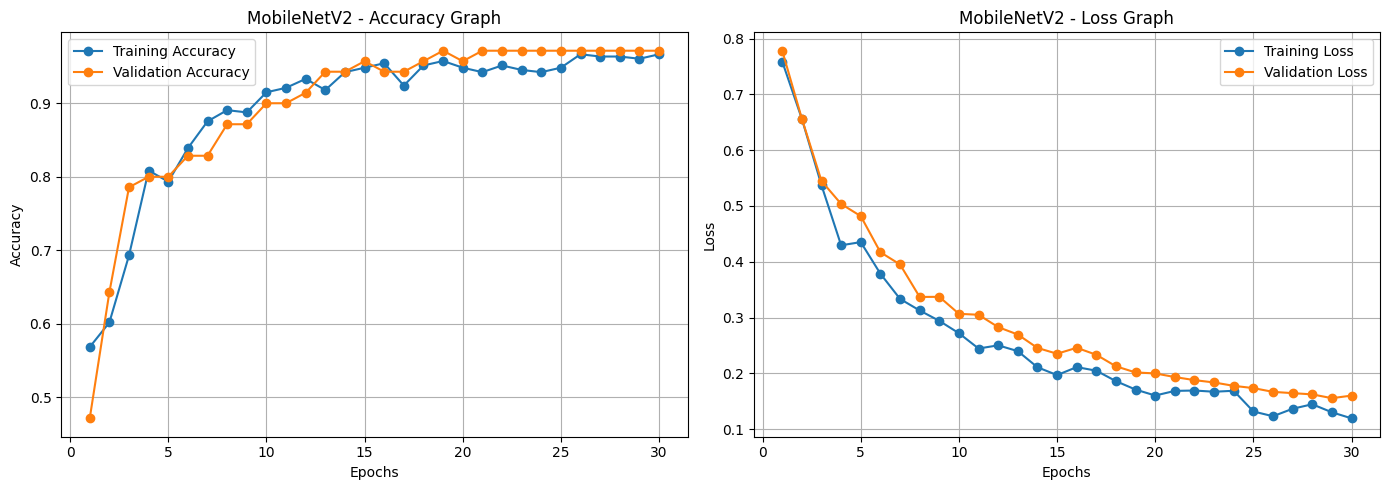

In [17]:

import matplotlib.pyplot as plt

# MobileNetV2 training history
history = history_mobilenet.history

epochs = range(1, len(history["accuracy"]) + 1)

plt.figure(figsize=(14, 5))

# Accuracy Graph
plt.subplot(1, 2, 1)
plt.plot(epochs, history["accuracy"],
         marker="o", label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"],
         marker="o", label="Validation Accuracy")

plt.title("MobileNetV2 - Accuracy Graph")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss Graph
plt.subplot(1, 2, 2)
plt.plot(epochs, history["loss"],
         marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"],
         marker="o", label="Validation Loss")

plt.title("MobileNetV2 - Loss Graph")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

# Save graph for project report
plt.savefig(
    "/content/mobilenet_training_graphs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


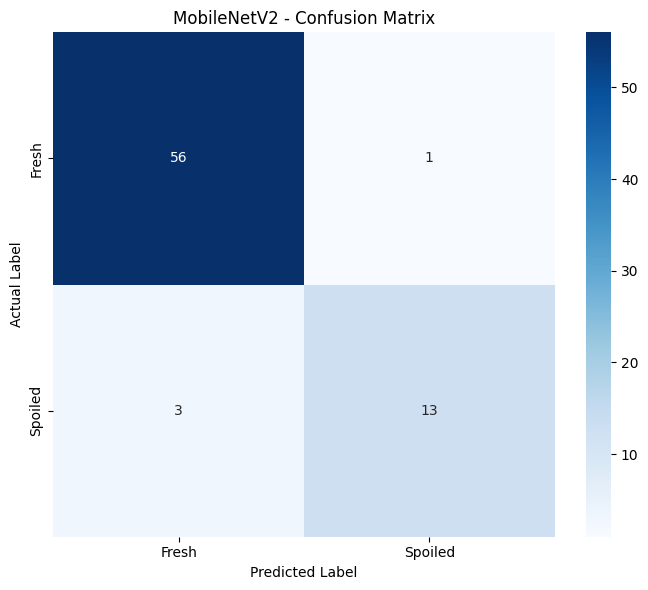

In [18]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

y_true = []
y_pred = []

for images, labels in test_ds:
    probs = mobilenet_model.predict(images, verbose=0).ravel()

    y_true.extend(labels.numpy().astype(int).ravel())
    y_pred.extend((probs >= 0.5).astype(int))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fresh", "Spoiled"],
    yticklabels=["Fresh", "Spoiled"]
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    "/content/mobilenet_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


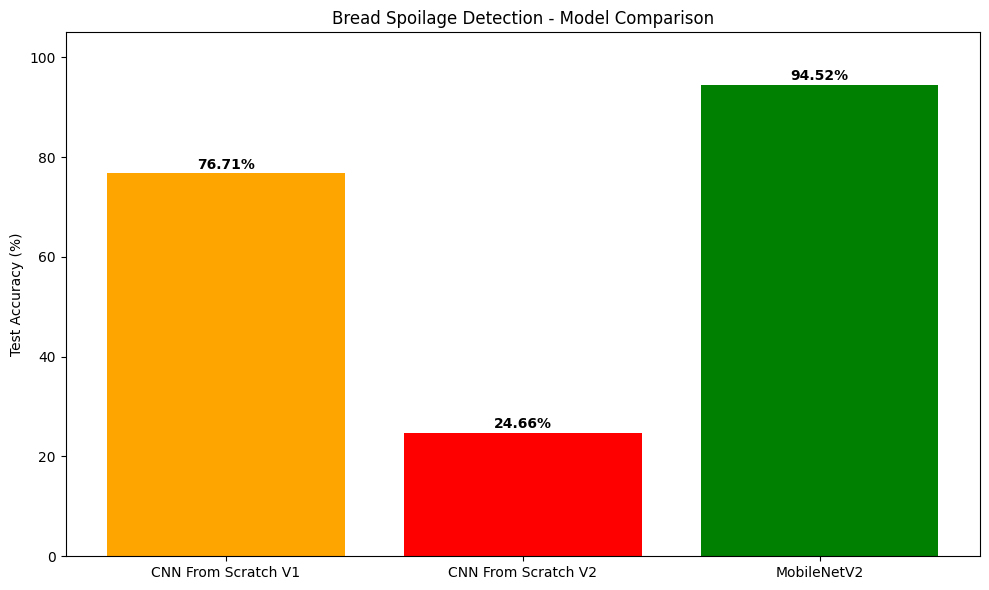

In [19]:

import matplotlib.pyplot as plt

models = [
    "CNN From Scratch V1",
    "CNN From Scratch V2",
    "MobileNetV2"
]

test_accuracies = [76.71, 24.66, 94.52]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    models,
    test_accuracies,
    color=["orange", "red", "green"]
)

plt.title("Bread Spoilage Detection - Model Comparison")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 105)

for bar, accuracy in zip(bars, test_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

plt.savefig(
    "/content/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [20]:

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

augmentation_v3 = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
])

scratch_v3 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    augmentation_v3,
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

scratch_v3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

scratch_v3.summary()

print("CNN From Scratch V3 ready!")


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 422,881 (1.61 MB)

 Trainable params: 421,921 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

CNN From Scratch V3 ready!


In [21]:

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks_v3 = [
    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=0.000001
    ),

    ModelCheckpoint(
        "/content/best_scratch_v3.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_v3 = scratch_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    class_weight=class_weights,
    callbacks=callbacks_v3
)


Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 129ms/step - accuracy: 0.7295 - loss: 0.5905 - precision: 0.4087 - recall: 0.6912 - val_accuracy: 0.7857 - val_loss: 0.6555 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 3.0000e-04
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - accuracy: 0.7964 - loss: 0.4323 - precision: 0.5042 - recall: 0.8824 - val_accuracy: 0.2571 - val_loss: 0.7033 - val_precision: 0.2031 - val_recall: 0.9286 - learning_rate: 3.0000e-04
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 99ms/step - accuracy: 0.8419 - loss: 0.4084 - precision: 0.5833 - recall: 0.8235 - val_accuracy: 0.7429 - val_loss: 0.6596 - val_precision: 0.3750 - val_recall: 0.4286 - learning_rate: 3.0000e-04
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.8085 - loss: 0.4127 - precision: 0.5238 - recall: 0.8088 - val_accuracy: 0.2000 - val_loss: 0.7778 - val_precision: 0.2000 - val_recall: 1.0000 - learning_rate: 3.0000e-04
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 1

In [22]:

import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Training, Validation, Testing Accuracy
train_results = scratch_v3.evaluate(train_ds, verbose=0)
val_results = scratch_v3.evaluate(val_ds, verbose=0)
test_results = scratch_v3.evaluate(test_ds, verbose=0)

print("=== CNN From Scratch V3 ===")
print(f"Training Accuracy: {train_results[1]*100:.2f}%")
print(f"Validation Accuracy: {val_results[1]*100:.2f}%")
print(f"Testing Accuracy: {test_results[1]*100:.2f}%")

# Test predictions
y_true = []
y_pred = []

for images, labels in test_ds:
    probs = scratch_v3.predict(images, verbose=0).ravel()

    y_true.extend(labels.numpy().astype(int).ravel())
    y_pred.extend((probs >= 0.5).astype(int))

print("\n=== Confusion Matrix ===")
print(confusion_matrix(y_true, y_pred))

print("\n=== Classification Report ===")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Fresh", "Spoiled"],
    digits=3,
    zero_division=0
))


=== CNN From Scratch V3 ===
Training Accuracy: 79.64%
Validation Accuracy: 78.57%
Testing Accuracy: 78.08%

=== Confusion Matrix ===
[[57  0]
 [16  0]]

=== Classification Report ===
              precision    recall  f1-score   support

       Fresh      0.781     1.000     0.877        57
     Spoiled      0.000     0.000     0.000        16

    accuracy                          0.781        73
   macro avg      0.390     0.500     0.438        73
weighted avg      0.610     0.781     0.685        73



In [23]:

import numpy as np

print("=== CLASS MAPPING ===")
print("Classes:", train_ds.class_names if hasattr(train_ds, "class_names") else "Fresh=0, Spoiled=1")

print("\n=== TRAINING CLASS COUNTS ===")
print("Fresh:", fresh_count)
print("Spoiled:", spoiled_count)
print("Class weights:", class_weights)

print("\n=== CNN V3 TRAINING HISTORY ===")
for i in range(len(history_v3.history["loss"])):
    print(
        f"Epoch {i+1}: "
        f"loss={history_v3.history['loss'][i]:.4f}, "
        f"val_loss={history_v3.history['val_loss'][i]:.4f}, "
        f"accuracy={history_v3.history['accuracy'][i]:.4f}, "
        f"val_accuracy={history_v3.history['val_accuracy'][i]:.4f}"
    )

print("\n=== CNN V3 PREDICTION PROBABILITIES ===")

fresh_probs = []
spoiled_probs = []

for images, labels in test_ds:
    probs = scratch_v3.predict(images, verbose=0).ravel()
    actual = labels.numpy().astype(int).ravel()

    fresh_probs.extend(probs[actual == 0])
    spoiled_probs.extend(probs[actual == 1])

print("Fresh average Spoiled probability:",
      round(np.mean(fresh_probs), 4))

print("Spoiled average Spoiled probability:",
      round(np.mean(spoiled_probs), 4))

print("Fresh probability range:",
      round(np.min(fresh_probs), 4),
      "to",
      round(np.max(fresh_probs), 4))

print("Spoiled probability range:",
      round(np.min(spoiled_probs), 4),
      "to",
      round(np.max(spoiled_probs), 4))


=== CLASS MAPPING ===
Classes: Fresh=0, Spoiled=1

=== TRAINING CLASS COUNTS ===
Fresh: 261
Spoiled: 68
Class weights: {0: 0.6302681992337165, 1: 2.4191176470588234}

=== CNN V3 TRAINING HISTORY ===
Epoch 1: loss=0.5905, val_loss=0.6555, accuracy=0.7295, val_accuracy=0.7857
Epoch 2: loss=0.4323, val_loss=0.7033, accuracy=0.7964, val_accuracy=0.2571
Epoch 3: loss=0.4084, val_loss=0.6596, accuracy=0.8419, val_accuracy=0.7429
Epoch 4: loss=0.4127, val_loss=0.7778, accuracy=0.8085, val_accuracy=0.2000
Epoch 5: loss=0.4293, val_loss=0.7554, accuracy=0.8389, val_accuracy=0.2000
Epoch 6: loss=0.3754, val_loss=0.8818, accuracy=0.8116, val_accuracy=0.2000
Epoch 7: loss=0.3225, val_loss=0.8528, accuracy=0.8511, val_accuracy=0.2000
Epoch 8: loss=0.3017, val_loss=0.7993, accuracy=0.8784, val_accuracy=0.2000
Epoch 9: loss=0.3308, val_loss=0.8021, accuracy=0.8815, val_accuracy=0.2000
Epoch 10: loss=0.3001, val_loss=0.7298, accuracy=0.8663, val_accuracy=0.2286
Epoch 11: loss=0.3295, val_loss=0.7268, 

=== DATASET COUNTS ===

TRAIN
fresh: 261
spoiled: 68

VAL
fresh: 56
spoiled: 14

TEST
fresh: 57
spoiled: 16

=== SAMPLE TRAINING IMAGES ===


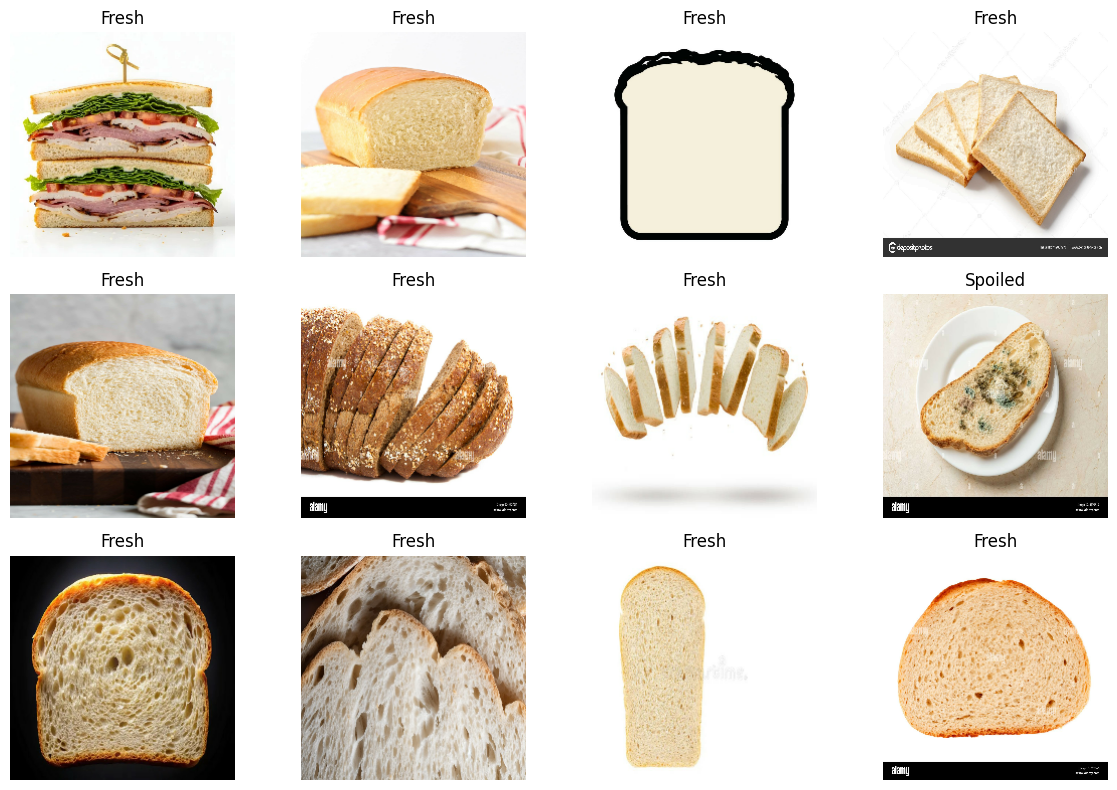

In [24]:

from pathlib import Path
import matplotlib.pyplot as plt
import tensorflow as tf

print("=== DATASET COUNTS ===")

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")
    for cls in ["fresh", "spoiled"]:
        folder = root / split / cls
        files = [
            p for p in folder.iterdir()
            if p.is_file()
        ]
        print(f"{cls}: {len(files)}")

print("\n=== SAMPLE TRAINING IMAGES ===")

plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i].numpy().item())
        title = "Fresh" if label == 0 else "Spoiled"

        plt.title(title)
        plt.axis("off")

plt.tight_layout()
plt.show()


In [25]:

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)

tf.keras.utils.set_random_seed(42)

# Fresh=0, Spoiled=1
# Pretrained weights bilkul nahi hain
scratch_v4 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

scratch_v4.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

callbacks_v4 = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    ),
    ModelCheckpoint(
        "/content/best_scratch_v4.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_v4 = scratch_v4.fit(
    train_ds,
    validation_data=val_ds,
    epochs=35,
    class_weight=class_weights,
    callbacks=callbacks_v4
)


Epoch 1/35
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 146ms/step - accuracy: 0.6991 - loss: 0.7077 - val_accuracy: 0.2000 - val_loss: 0.7537 - learning_rate: 1.0000e-04
Epoch 2/35
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 0.2948 - loss: 0.6979 - val_accuracy: 0.2429 - val_loss: 0.6998 - learning_rate: 1.0000e-04
Epoch 3/35
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.5897 - loss: 0.6861 - val_accuracy: 0.8000 - val_loss: 0.6291 - learning_rate: 1.0000e-04
Epoch 4/35
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - accuracy: 0.7660 - loss: 0.6703 - val_accuracy: 0.8143 - val_loss: 0.5944 - learning_rate: 1.0000e-04
Epoch 5/35
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.7234 - loss: 0.6135 - val_accuracy: 0.8143 - val_loss: 0.4819 - learning_rate: 1.0000e-04
Epoch 6/35
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step - accuracy: 0.7538 - loss: 0.5871 - val_accuracy: 0.6857 - val_loss: 0.6059 - learning_rate: 1.0000e-04
Epoch 7/35
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - accuracy: 0

In [26]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

print("=== CNN V4 Accuracy ===")

for name, ds in [
    ("Training", train_ds),
    ("Validation", val_ds),
    ("Testing", test_ds)
]:
    loss, acc = scratch_v4.evaluate(ds, verbose=0)
    print(f"{name}: {acc*100:.2f}%")

y_true, y_pred = [], []

for images, labels in test_ds:
    probs = scratch_v4.predict(images, verbose=0).ravel()
    y_true.extend(labels.numpy().astype(int).ravel())
    y_pred.extend((probs >= 0.5).astype(int))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=["Fresh", "Spoiled"],
    zero_division=0
))


=== CNN V4 Accuracy ===
Training: 92.40%
Validation: 90.00%
Testing: 89.04%

Confusion Matrix:
[[53  4]
 [ 4 12]]

Classification Report:
              precision    recall  f1-score   support

       Fresh       0.93      0.93      0.93        57
     Spoiled       0.75      0.75      0.75        16

    accuracy                           0.89        73
   macro avg       0.84      0.84      0.84        73
weighted avg       0.89      0.89      0.89        73



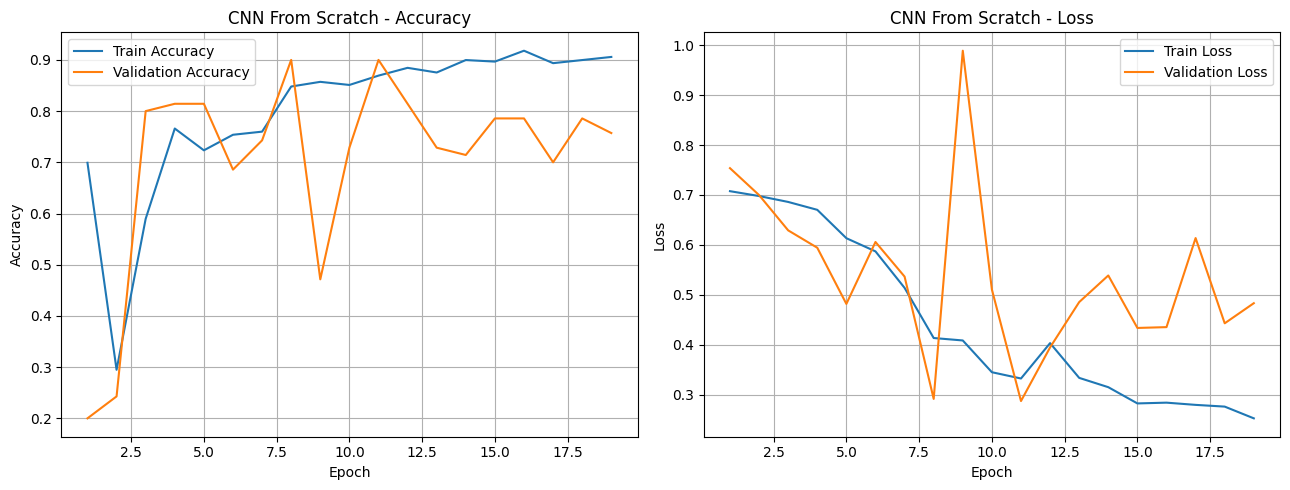

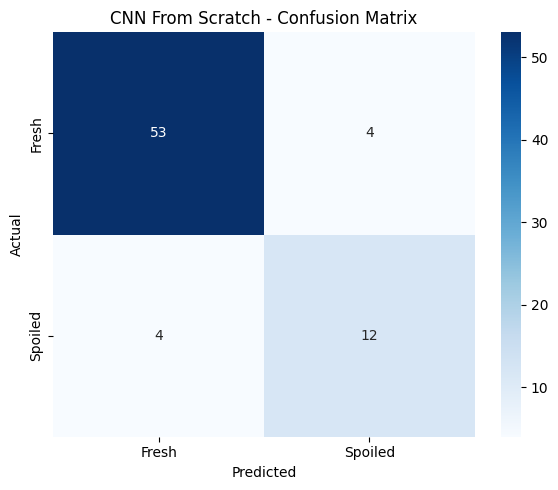

CNN V4 model and graphs saved!


In [27]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Accuracy & Loss graphs
h = history_v4.history
epochs = range(1, len(h["accuracy"]) + 1)

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, h["accuracy"], label="Train Accuracy")
plt.plot(epochs, h["val_accuracy"], label="Validation Accuracy")
plt.title("CNN From Scratch - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, h["loss"], label="Train Loss")
plt.plot(epochs, h["val_loss"], label="Validation Loss")
plt.title("CNN From Scratch - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("/content/cnn_v4_training_graphs.png", dpi=300)
plt.show()

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Fresh", "Spoiled"],
    yticklabels=["Fresh", "Spoiled"]
)
plt.title("CNN From Scratch - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("/content/cnn_v4_confusion_matrix.png", dpi=300)
plt.show()

# Save model
scratch_v4.save("/content/bread_scratch_cnn.keras")

print("CNN V4 model and graphs saved!")


In [29]:

from google.colab import files
import os

download_files = [
    "bread_scratch_cnn.keras",
    "best_mobilenetv2.keras",
    "cnn_v4_training_graphs.png",
    "cnn_v4_confusion_matrix.png",
    "mobilenet_training_graphs.png",
    "mobilenet_confusion_matrix.png",
    "model_comparison.png"
]

for filename in download_files:
    path = "/content/" + filename

    if os.path.exists(path):
        print("Downloading:", filename)
        files.download(path)
    else:
        print("Not found:", filename)


Downloading: bread_scratch_cnn.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: best_mobilenetv2.keras


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: model_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model loaded successfully!


Saving b2.jfif to b2.jfif


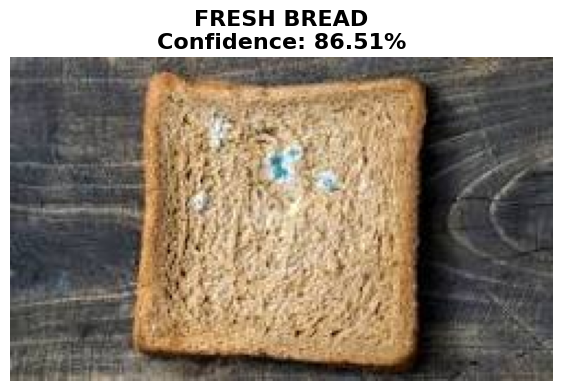

Prediction: FRESH BREAD
Confidence: 86.51%
Spoiled Probability: 13.49%


In [31]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from PIL import Image
from pathlib import Path

# Best MobileNetV2 model load karo
model = tf.keras.models.load_model(
    "/content/best_mobilenetv2.keras"
)

print("Model loaded successfully!")

# Laptop se bread image upload karo
uploaded = files.upload()

for filename in uploaded.keys():

    # Image open aur resize
    image = Image.open(filename).convert("RGB")
    image_resized = image.resize((224, 224))

    # Model input
    img_array = np.array(
        image_resized,
        dtype=np.float32
    )

    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    probability = float(
        model.predict(img_array, verbose=0)[0][0]
    )

    if probability >= 0.5:
        prediction = "SPOILED BREAD"
        confidence = probability * 100
    else:
        prediction = "FRESH BREAD"
        confidence = (1 - probability) * 100

    # Result display
    plt.figure(figsize=(7, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"{prediction}\nConfidence: {confidence:.2f}%",
        fontsize=16,
        fontweight="bold"
    )
    plt.show()

    print("Prediction:", prediction)
    print(f"Confidence: {confidence:.2f}%")
    print(f"Spoiled Probability: {probability*100:.2f}%")
